# 📦 Forecasting Weekly Product Demand for an Online Gift Retailer

**Problem:** We're forecasting how many units of each product a UK online gift-ware retailer will sell in each of the coming weeks.
 This is a **time series forecasting** problem: the target is a number (weekly units), and the order of time matters. 
 The forecast is then used for a business decision: how much stock to keep (safety stock and reorder point).

**Dataset:** Online Retail II (UCI Machine Learning Repository, CC BY 4.0; Chen 2012, DOI 10.24432/C5CG6D).
About 1.07 million invoice lines from December 2009 to December 2011, stored in one Excel file with one sheet per year.
 The data is real and messy (cancellations, duplicates, zero prices, non-product codes), so cleaning it properly is a big part of this notebook.


## 1. Import Libraries

We only import what this notebook needs: `pandas` and `numpy` for data handling,
 `matplotlib` for quick checks, 
 `pathlib` for file paths that work on any computer.

In [71]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

# notebook is inside /notebooks, so project root is one level up
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_XLSX = ROOT / "data" / "raw" / "online_retail_II.xlsx"
PROCESSED_DIR = ROOT / "data" / "processed"
RAW_CACHE = PROCESSED_DIR / "raw_combined.parquet"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Raw file found:", RAW_XLSX.exists())

Raw file found: True


## 2. Load the Dataset

The Excel file has **two sheets** (2009-2010 and 2010-2011), so we read both and stack them into one table.

Reading a 46 MB Excel file takes a few minutes, so after the first read we save a **parquet copy** (a fast, compressed file format).
 Every re-run after that loads in seconds.

`Invoice` and `StockCode` mix numbers (`489434`) and text (`C489449`, `79323P`), so we store them as text to keep every code exactly as written.

In [72]:
if RAW_CACHE.exists():
    df = pd.read_parquet(RAW_CACHE)
    print("Loaded from parquet copy.")
else:
    start = time.time()
    sheets = pd.read_excel(RAW_XLSX, sheet_name=None)   # None = read all sheets
    for name, sheet in sheets.items():
        print(f"Sheet '{name}': {len(sheet):,} rows")
    df = pd.concat(sheets.values(), ignore_index=True)

    # mixed number/text columns -> text
    for col in ["Invoice", "StockCode", "Description", "Country"]:
        df[col] = df[col].astype("string")

    df.to_parquet(RAW_CACHE, index=False)
    print(f"Read Excel in {time.time() - start:.0f} seconds and saved a parquet copy.")

Loaded from parquet copy.


In [73]:
# number of rows and columns
df.shape

(1067371, 8)

In [74]:
# first 5 rows
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [75]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  string        
 1   StockCode    1067371 non-null  string        
 2   Description  1062989 non-null  string        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  string        
dtypes: datetime64[us](1), float64(2), int64(1), string(4)
memory usage: 117.3 MB


In [76]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


📌 **Reading this:**
- **1,067,371 rows and 8 columns.** Each row is one product line on one invoice, not one whole order.
- **Dates run from 2009-12-01 to 2011-12-09**, so we have about two years of history. December 2011 is only a partial month (the data stops on 9 December).
- **Missing values:** `Description` is missing in 4,382 rows, and `Customer ID` is missing in 243,007 rows (about 22.8%). Missing customer IDs are guest checkouts. That does not matter for us, because we forecast demand per **product**, not per customer.
- **Quantity looks suspicious:** the median is only 3 units, but the minimum is **-80,995** and the maximum is **+80,995**. The same number with opposite signs suggests one huge order that was later cancelled. Negative quantities usually mean cancellations or returns.
- **Price looks suspicious too:** the minimum is **-53,594.36**. A negative price is not a real sale; it is probably an accounting adjustment.

So the data clearly needs cleaning before we can trust any demand number. The next section audits each problem one by one.

## 3. Data Audit

Before changing anything, we **count** every problem in the raw data. Nothing is removed in this section. Measuring first means every cleaning decision later is backed by a number, and we can show exactly how much data each rule removes.

### 3.1 — Missing values

Which columns have gaps, and how big are they?

In [77]:
missing = pd.DataFrame({
    "missing": df.isnull().sum(),
    "percent": (df.isnull().mean() * 100).round(2)
})
missing

,missing,percent
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


📌 **Reading this:** Only two columns have gaps. `Description` is missing in 4,382 rows (0.41%), which is tiny; we'll check below what kind of rows these are. `Customer ID` is missing in 243,007 rows (22.77%). These are guest checkouts, and since we forecast demand per **product**, not per customer, we keep these rows. Dropping them would throw away almost a quarter of real sales.

### 3.2 — Duplicate rows

Are there rows that are exact copies of another row (same invoice, product, quantity, time, price, customer)?

In [78]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

Exact duplicate rows: 34,335


📌 **Reading this:** 34,335 rows are exact copies of another row: same invoice, product, quantity, time, price and customer. A real order line would not be entered twice in the same second, so these are recording errors. If we kept them, the demand for those products would be counted twice, so they will be removed in the cleaning step.

### 3.3 — Cancelled invoices

In this dataset, an invoice number starting with **"C"** means the order was cancelled. How many such lines are there, and what do their quantities look like?

In [79]:
# invoices starting with "C" are cancellations
is_cancel = df["Invoice"].str.startswith("C")

print(f"Cancellation lines   : {is_cancel.sum():,}")
print(f"Cancellation invoices: {df.loc[is_cancel, 'Invoice'].nunique():,}")
df.loc[is_cancel, "Quantity"].describe()

Cancellation lines   : 19,494
Cancellation invoices: 8,292


count    19494.000000
mean       -25.186827
std        805.104908
min     -80995.000000
25%         -6.000000
50%         -2.000000
75%         -1.000000
max          1.000000
Name: Quantity, dtype: float64

📌 **Reading this:** 19,494 lines (8,292 invoices) are cancellations. Almost all of them have **negative** quantities (median -2): they reverse an earlier sale. The minimum, **-80,995**, matches the +80,995 maximum we saw in `describe()`, which confirms one huge order was placed and then fully cancelled. Cancellations are not demand, so they will be removed. We'll also need to remove the original sale that a cancellation reversed, otherwise that +80,995 order would still look like real demand.

### 3.4 — Negative quantities that are not cancellations

A negative quantity on a normal invoice (not starting with "C") is strange. What are these rows?

In [80]:
neg_not_cancel = (~is_cancel) & (df["Quantity"] < 0)

print(f"Negative quantity, not a cancellation: {neg_not_cancel.sum():,}")
df.loc[neg_not_cancel, ["StockCode", "Description", "Quantity", "Price", "Customer ID"]].head(10)

Negative quantity, not a cancellation: 3,457


,StockCode,Description,Quantity,Price,Customer ID
263,21733,85123a mixed,-96,0.0,NaN
283,71477,short,-240,0.0,NaN
284,85123A,21733 mixed,-192,0.0,NaN
470,21646,<NA>,-50,0.0,NaN
3114,20683,<NA>,-44,0.0,NaN
3162,35956,lost,-1043,0.0,NaN
3168,35605A,damages,-117,0.0,NaN
4296,18010,<NA>,-770,0.0,NaN
4538,21133,invcd as 84879?,-720,0.0,NaN
4566,85049G,<NA>,-240,0.0,NaN


📌 **Reading this:** 3,457 lines have a negative quantity on a normal invoice. Every row shown has **price 0** and **no customer**, and the descriptions are notes like *"lost"*, *"damages"*, *"short"* and *"mixed"*. These are warehouse **stock adjustments**, not customers returning goods, so they are not demand and will be removed.

### 3.5 — Zero and negative prices

A real sale should have a price above zero. How many lines break that rule?

In [81]:
print(f"Price = 0 : {(df['Price'] == 0).sum():,}")
print(f"Price < 0 : {(df['Price'] < 0).sum():,}")

# look at the negative-price rows
df.loc[df["Price"] < 0, ["Invoice", "StockCode", "Description", "Quantity", "Price"]]

Price = 0 : 6,202
Price < 0 : 5


,Invoice,StockCode,Description,Quantity,Price
179403,A506401,B,Adjust bad debt,1,-53594.36
276274,A516228,B,Adjust bad debt,1,-44031.79
403472,A528059,B,Adjust bad debt,1,-38925.87
825444,A563186,B,Adjust bad debt,1,-11062.06
825445,A563187,B,Adjust bad debt,1,-11062.06


📌 **Reading this:** 6,202 lines have a price of 0 and 5 have a negative price. The 5 negative-price rows are all *"Adjust bad debt"* entries with stock code `B` and invoice numbers starting with **"A"**. These are accounting corrections, not sales. Zero-price lines are not paid sales either; many of them are the stock adjustments from 3.4. All lines with price ≤ 0 will be removed.

### 3.6 — Non-product stock codes

Real products have stock codes that start with 5 digits (for example `85048` or `79323P`). Other codes, such as postage or bank charges, are not products. Which of these codes appear, and how often?

In [82]:
# real product codes start with 5 digits
is_product_code = df["StockCode"].str.match(r"^\d{5}")

print(f"Lines with a non-product code: {(~is_product_code).sum():,}")
df.loc[~is_product_code, "StockCode"].value_counts().head(20)

Lines with a non-product code: 6,093


StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
gift_0001_10      16
CRUK              16
DCGS0076          15
TEST001           15
DCGS0003          14
Name: count, dtype: int64[pyarrow]

📌 **Reading this:** 6,093 lines use a code that is not a normal product. The biggest ones are clearly not products: `POST` and `DOT` (postage), `M` (manual entry), `C2` (carriage), `D` (discount), `S` (samples), `BANK CHARGES`, `ADJUST`, `AMAZONFEE`, `TEST001` and `gift_0001_*` (gift vouchers). A few codes like `DCGS...` may be small real items, but they sell very rarely and will never be among the top products we forecast. We remove all non-product codes, so that the demand we model is only for physical products.

### 3.7 — Rows with a missing description

In 3.1 we saw 4,382 rows without a `Description`. What kind of rows are they?

In [83]:
no_desc = df["Description"].isna()

print(f"Rows with missing description: {no_desc.sum():,}")
print(f"...of which have price 0     : {(no_desc & (df['Price'] == 0)).sum():,}")

Rows with missing description: 4,382
...of which have price 0     : 4,382


📌 **Reading this:** All 4,382 rows without a description also have **price 0**. They are not real sales, so the "price ≤ 0" rule will remove them automatically. We don't need a separate rule for missing descriptions.

### 3.8 — Lower-case letters in product codes

Some product codes end in a letter for a colour or size variant (for example `85123A`). If the same product is sometimes written `85123a`, it would be counted as two different products. How often does this happen?

In [84]:
# product codes that contain a lower-case letter
has_lower = is_product_code & df["StockCode"].str.contains(r"[a-z]", regex=True)

print(f"Product lines with lower-case letters: {has_lower.sum():,}")
df.loc[has_lower, "StockCode"].value_counts().head(10)

Product lines with lower-case letters: 3,366


StockCode
18098c     142
72349b     121
15056n     121
47566b     116
84970s     103
85123a     101
15056bl     93
84997b      90
82494l      88
84997d      86
Name: count, dtype: int64[pyarrow]

📌 **Reading this:** 3,366 product lines have lower-case letters, for example `85123a`, `72349b` and `15056bl`. These are the same products as `85123A`, `72349B` and `15056BL`, just typed differently. If we left them as they are, one product's sales would be split across two codes. We'll convert all stock codes to upper-case before grouping.

### 3.9 — Very large order lines

The median line is only a few units. How big do the largest lines get, and how many are there?

In [85]:
q = df.loc[~is_cancel & (df["Quantity"] > 0), "Quantity"]
print(q.quantile([0.50, 0.90, 0.99, 0.999]))

big = q >= 1000
print(f"\nLines with 1,000+ units: {big.sum():,}")

# the 10 biggest lines
df.loc[q[big].index].sort_values("Quantity", ascending=False)[
    ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Customer ID"]
].head(10)

0.500      3.0
0.900     24.0
0.990    108.0
0.999    500.0
Name: Quantity, dtype: float64

Lines with 1,000+ units: 384


,Invoice,StockCode,Description,Quantity,InvoiceDate,Customer ID
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,16446.0
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,12346.0
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,13902.0
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,13902.0
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,13902.0
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,13902.0
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,13256.0
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,13902.0
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,2010-05-10 14:55:00,NaN
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,2010-03-23 15:36:00,17940.0


📌 **Reading this:** A typical line is small: the median is 3 units, 99% of lines are 108 units or fewer, and 99.9% are 500 or fewer. But **384 lines have 1,000+ units**. The two largest (80,995 and 74,215 units) match the cancellations we found in 3.3; they were ordered and then fully cancelled, so they are not real demand. Many of the others look like genuine wholesale orders (for example, customer 13902 bought about 12,000-13,000 units each of several paper party items in one order). We will **not** delete large lines, because bulk buyers are real customers. Instead we'll flag them, and decide how to cap them when we build weekly demand.

### 3.10 — Audit summary

| Problem | Rows | Action |
|---|---|---|
| Exact duplicate rows | 34,335 | Remove |
| Lower-case product codes | 3,366 | Convert to upper-case |
| Non-product codes (POST, DOT, M, BANK CHARGES ...) | 6,093 | Remove |
| Price = 0 (incl. all missing descriptions) | 6,202 | Remove |
| Price < 0 ("Adjust bad debt") | 5 | Remove |
| Cancelled invoices ("C...") | 19,494 | Remove |
| Negative quantity, not a cancellation (stock adjustments) | 3,457 | Remove |
| Sales that were later fully cancelled (e.g. +80,995 / -80,995) | to be measured | Remove |
| Missing Customer ID | 243,007 | Keep (we forecast per product) |
| Very large lines (1,000+ units) | 384 | Keep and flag |

These groups overlap (for example, a stock adjustment can have both a negative quantity and price 0), so the rows removed in the cleaning steps will not simply add up to the numbers above.

## 4. Data Cleaning

We apply one rule at a time, in a fixed order, on a copy of the raw data. After every rule we record how many rows were removed in a **cleaning log**, so the whole cleaning process can be checked and explained.

In [86]:
cleaning_log = []

def log_step(step, rows_before, rows_after):
    cleaning_log.append({
        "step": step,
        "rows_before": rows_before,
        "rows_after": rows_after,
        "rows_removed": rows_before - rows_after,
    })
    print(f"{step}: removed {rows_before - rows_after:,} rows -> {rows_after:,} rows left")

# work on a copy, keep the raw data untouched
clean = df.copy()
log_step("0. raw data", len(clean), len(clean))

0. raw data: removed 0 rows -> 1,067,371 rows left


### 4.1 — Remove exact duplicates

In [87]:
before = len(clean)
clean = clean.drop_duplicates()
log_step("1. drop exact duplicates", before, len(clean))

1. drop exact duplicates: removed 34,335 rows -> 1,033,036 rows left


### 4.2 — Standardise stock codes

Convert codes to upper-case and remove stray spaces, so `85123a` and `85123A` become the same product. No rows are removed here.

In [88]:
before = len(clean)
clean["StockCode"] = clean["StockCode"].str.strip().str.upper()
log_step("2. upper-case stock codes", before, len(clean))

2. upper-case stock codes: removed 0 rows -> 1,033,036 rows left


### 4.3 — Remove non-product codes

Keep only codes that start with 5 digits (real products). This removes postage, fees, manual entries, discounts and gift vouchers.

In [89]:
before = len(clean)
clean = clean[clean["StockCode"].str.match(r"^\d{5}")]
log_step("3. drop non-product codes", before, len(clean))

3. drop non-product codes: removed 5,980 rows -> 1,027,056 rows left


### 4.4 — Remove lines with price ≤ 0

A real sale has a positive price. This also removes every row with a missing description (3.7) and most stock adjustments (3.4).

In [90]:
before = len(clean)
clean = clean[clean["Price"] > 0]
log_step("4. drop price <= 0", before, len(clean))

print(f"\nMissing descriptions left: {clean['Description'].isna().sum():,}")

4. drop price <= 0: removed 5,928 rows -> 1,021,128 rows left

Missing descriptions left: 0


### 4.5 — Remove cancellations and returns

Cancelled invoices ("C...") and any remaining negative quantities are not demand, so we remove them. Before removing them, we keep a copy of the cancellations that have a customer ID, because we need them in the next step.

In [91]:
is_cancel = clean["Invoice"].str.startswith("C")

# keep cancellations with a customer ID for matching in 4.6 (quantity made positive)
cancels = clean[is_cancel & clean["Customer ID"].notna() & (clean["Quantity"] < 0)].copy()
cancels["Quantity"] = -cancels["Quantity"]
print(f"Cancellation lines kept for matching: {len(cancels):,}\n")

before = len(clean)
clean = clean[~is_cancel & (clean["Quantity"] > 0)]
log_step("5. drop cancellations and returns", before, len(clean))

Cancellation lines kept for matching: 17,586

5. drop cancellations and returns: removed 17,914 rows -> 1,003,214 rows left


📌 **Reading this:** 17,914 cancellation and negative-quantity lines were removed. We kept 17,586 of the cancellations (the ones with a customer ID) aside, to match them to their original sales in the next step.

### 4.6 — Remove sales that were cancelled later

Removing a cancellation line is not enough: the **original sale** it reversed is still in the data. For example, the +80,995 order would still look like real demand.

We match each cancellation to an earlier sale with the **same customer, product and quantity**, where the sale happened on or before the cancellation. Each cancellation removes at most one sale.

**Limitation:** partial cancellations (e.g. 100 ordered, 20 cancelled) and cancellations without a customer ID cannot be matched safely, so those sales are kept.

In [92]:
keys = ["Customer ID", "StockCode", "Quantity"]

sales = clean[clean["Customer ID"].notna()].sort_values("InvoiceDate").copy()
cancels = cancels.sort_values("InvoiceDate")

# number repeated (customer, product, quantity) rows 0, 1, 2 ... so each cancellation matches only one sale
sales["match_no"] = sales.groupby(keys).cumcount()
cancels["match_no"] = cancels.groupby(keys).cumcount()

pairs = sales.reset_index().merge(
    cancels[keys + ["match_no", "InvoiceDate"]],
    on=keys + ["match_no"],
    suffixes=("", "_cancel"),
)
# the sale must happen on or before its cancellation
pairs = pairs[pairs["InvoiceDate"] <= pairs["InvoiceDate_cancel"]]

print(f"Sales matched to a later cancellation: {len(pairs):,} lines, {pairs['Quantity'].sum():,} units\n")

before = len(clean)
clean = clean.drop(index=pairs["index"])
log_step("6. drop sales cancelled later", before, len(clean))

Sales matched to a later cancellation: 6,180 lines, 404,917 units

6. drop sales cancelled later: removed 6,180 rows -> 997,034 rows left


In [93]:
# check: the two huge ordered-then-cancelled lines should now be gone
clean["Quantity"].nlargest(5)

90857     19152
127166    12960
127168    12960
127169    12744
127167    12480
Name: Quantity, dtype: int64

📌 **Reading this:** 6,180 sales (404,917 units) were matched to a later cancellation and removed. That is a lot of fake demand: without this step, those units would have looked like real sales. The check confirms the two huge ordered-then-cancelled lines (80,995 and 74,215 units) are gone. The largest line left is a 19,152-unit wholesale order of mugs, which is a genuine sale.

### 4.7 — Final duplicate check

After upper-casing stock codes, two rows can become identical except for small spelling differences in `Description`. We check for duplicates once more, ignoring the description.

In [94]:
cols_without_desc = [c for c in clean.columns if c != "Description"]

before = len(clean)
clean = clean.drop_duplicates(subset=cols_without_desc)
log_step("7. drop duplicates ignoring description", before, len(clean))

7. drop duplicates ignoring description: removed 1 rows -> 997,033 rows left


📌 **Reading this:** Only 1 extra duplicate appeared after standardising stock codes, so the earlier steps already caught almost everything.

### 4.8 — Cleaning log

The full story of the cleaning in one table: how many rows each rule removed, and what share of the raw data is left.

In [95]:
log_df = pd.DataFrame(cleaning_log)
log_df["pct_of_raw_left"] = (log_df["rows_after"] / len(df) * 100).round(1)
log_df

,step,rows_before,rows_after,rows_removed,pct_of_raw_left
0,0. raw data,1067371,1067371,0,100.0
1,1. drop exact duplicates,1067371,1033036,34335,96.8
2,2. upper-case stock codes,1033036,1033036,0,96.8
3,3. drop non-product codes,1033036,1027056,5980,96.2
4,4. drop price <= 0,1027056,1021128,5928,95.7
5,5. drop cancellations and returns,1021128,1003214,17914,94.0
6,6. drop sales cancelled later,1003214,997034,6180,93.4
7,7. drop duplicates ignoring description,997034,997033,1,93.4


📌 **Reading this:** We kept **997,033 of 1,067,371 rows (93.4%)**. The two biggest removals were exact duplicates (34,335) and cancellations/returns (17,914). Every rule removed a clear, explainable group of rows, and no rows were dropped "just because they looked odd".

### 4.9 — Visual check: what did cleaning change?

Two quick plots: which rules removed the most rows, and how monthly units sold look before and after cleaning.

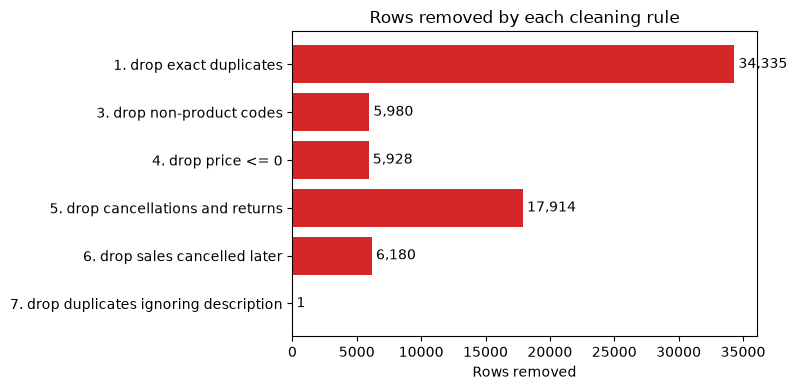

In [96]:
removed = log_df[log_df["rows_removed"] > 0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(removed["step"], removed["rows_removed"], color="tab:red")
ax.invert_yaxis()   # first rule on top
ax.set_xlabel("Rows removed")
ax.set_title("Rows removed by each cleaning rule")
for i, v in enumerate(removed["rows_removed"]):
    ax.text(v, i, f" {v:,}", va="center")
plt.tight_layout()
plt.show()

📌 **Reading this:** Duplicates were by far the largest problem, about twice the size of the next one. The last rule removed only 1 row, which shows the earlier rules had already caught almost everything.

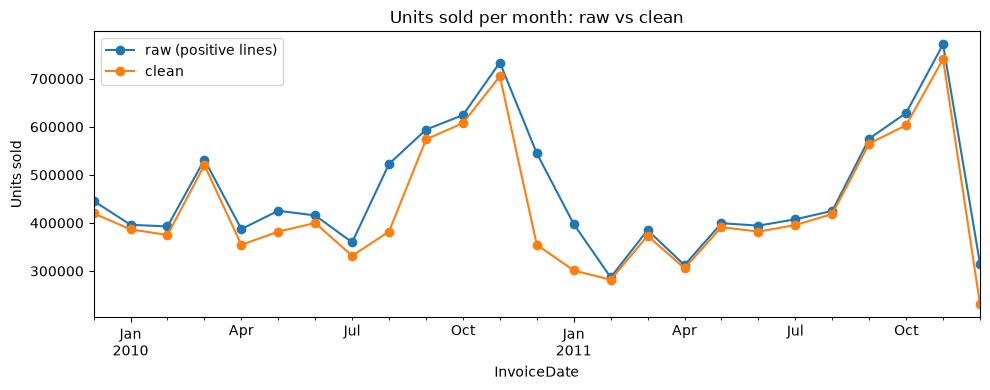

In [97]:
# raw: only positive lines, so cancellations don't cancel themselves out in the chart
raw_pos = df[df["Quantity"] > 0]

monthly = pd.DataFrame({
    "raw (positive lines)": raw_pos.groupby(raw_pos["InvoiceDate"].dt.to_period("M"))["Quantity"].sum(),
    "clean": clean.groupby(clean["InvoiceDate"].dt.to_period("M"))["Quantity"].sum(),
})

ax = monthly.plot(figsize=(10, 4), marker="o")
ax.set_ylabel("Units sold")
ax.set_title("Units sold per month: raw vs clean")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- For most months the two lines are close, so cleaning did not change the overall shape of the data.
- The biggest gaps are in **August 2010, December 2010, January 2011 and December 2011**, where raw data counted large orders that were later cancelled (for example the 74,215-unit order in January 2011 and the 80,995-unit order in December 2011). Without cleaning, a model would learn fake demand spikes in exactly those months.
- Both years show a clear **gift-season peak from September to November**, with the highest month in November. This yearly seasonality is the main pattern our forecast must capture.
- The last point (December 2011) drops sharply only because the data ends on 9 December. It is a **partial month, not a real fall in demand**, and we'll handle it when building weekly data.

## 5. Final Checks

Before saving, we confirm that every cleaning rule actually holds on the final data. If any line says FAIL, something went wrong above.

In [98]:
checks = {
    "no cancelled invoices": not clean["Invoice"].str.startswith("C").any(),
    "all quantities > 0": (clean["Quantity"] > 0).all(),
    "all prices > 0": (clean["Price"] > 0).all(),
    "all codes are products": clean["StockCode"].str.match(r"^\d{5}").all(),
    "no missing descriptions": clean["Description"].notna().all(),
    "no duplicate rows": not clean.duplicated().any(),
}

for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'} - {name}")

PASS - no cancelled invoices
PASS - all quantities > 0
PASS - all prices > 0
PASS - all codes are products
PASS - no missing descriptions
PASS - no duplicate rows


📌 **Reading this:** All six rules hold on the final data, so the cleaning steps did what they were meant to do.

## 6. Add Helper Columns

- `Revenue` = Quantity × Price, useful in EDA to see which products matter most in money terms.
- `is_large_line` = True for lines with 1,000+ units. We keep these sales (they are real wholesale orders), but flag them so we can decide how to cap them when building weekly demand.

In [99]:
clean["Revenue"] = clean["Quantity"] * clean["Price"]
clean["is_large_line"] = clean["Quantity"] >= 1000

print(f"Products   : {clean['StockCode'].nunique():,}")
print(f"Invoices   : {clean['Invoice'].nunique():,}")
print(f"Date range : {clean['InvoiceDate'].min():%Y-%m-%d} to {clean['InvoiceDate'].max():%Y-%m-%d}")
print(f"Units sold : {clean['Quantity'].sum():,}")
print(f"Large lines flagged: {clean['is_large_line'].sum():,}")

Products   : 4,700
Invoices   : 39,337
Date range : 2009-12-01 to 2011-12-09
Units sold : 10,782,557
Large lines flagged: 282


📌 **Reading this:** The clean data covers **4,700 products**, **39,337 invoices** and **10.78 million units** from 1 December 2009 to 9 December 2011. 282 lines with 1,000+ units are flagged as large wholesale orders.

## 7. Save the Clean Data

We save three files for the next notebooks:
- `clean_sales.parquet`: the cleaned transactions
- `product_names.csv`: one name per stock code (the most common description), used for labels in charts and in the app
- `cleaning_log.csv`: the cleaning log, for the README

In [100]:
# one name per product: its most common description
product_names = (
    clean.groupby("StockCode")["Description"]
    .agg(lambda s: s.str.strip().mode().iloc[0])
    .reset_index()
)

clean = clean.reset_index(drop=True)
clean.to_parquet(PROCESSED_DIR / "clean_sales.parquet", index=False)
product_names.to_csv(PROCESSED_DIR / "product_names.csv", index=False)
log_df.to_csv(PROCESSED_DIR / "cleaning_log.csv", index=False)

for f in ["clean_sales.parquet", "product_names.csv", "cleaning_log.csv"]:
    size_mb = (PROCESSED_DIR / f).stat().st_size / 1e6
    print(f"saved {f:22s} {size_mb:6.2f} MB")

saved clean_sales.parquet      7.88 MB
saved product_names.csv        0.17 MB
saved cleaning_log.csv         0.00 MB


## 8. Summary

**Final data:** 4,700 products, 39,337 invoices and 10.78 million units from 1 December 2009 to 9 December 2011, saved as `clean_sales.parquet`.

- Started with **1,067,371** raw invoice lines and kept **997,033 (93.4%)** after seven explainable cleaning rules.
- Removed: exact duplicates, non-product codes (postage, fees, vouchers), zero/negative prices (incl. bad-debt adjustments and stock write-offs), cancellations and returns, and **6,180 sales that were later cancelled** (404,917 units of fake demand).
- Standardised stock codes to upper-case so each product has one code.
- Kept rows without a customer ID (guest checkouts), because we forecast per product.
- Kept large wholesale lines but flagged them (`is_large_line`) for a capping decision later.

**Known limitations:**
- Only about two years of data, so just two yearly seasonal cycles to learn from.
- December 2011 is a partial month (data ends on 9 December).
- Partial cancellations and cancellations without a customer ID could not be matched to their original sale, so a small amount of cancelled demand may remain.

**Next (Part 2):** aggregate the clean transactions into **weekly demand per product**, choose the top products to forecast, and explore trend, seasonality and intermittent demand.